# CA3

### Imports

In [1]:
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import numpy as np 
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import copy


### Reading data

The code in this section has been reused from previous assignments

In [2]:
sample_sub = pd.read_csv("sample_submission.csv", sep=',')

sample_sub.head()

,ID,quality
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


In [3]:
train = pd.read_csv("train.csv", sep=',')

train.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,0,13
1,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9,0,705
2,8.1,0.290,0.36,2.2,0.048,35.0,53.0,0.99500,3.27,1.01,12.4,1,1408
3,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1,144
4,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0,557


In [4]:
test = pd.read_csv("test.csv", sep=',')

test.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,7.0,0.69,0.07,2.5,0.091,15.0,21.0,0.99572,3.38,0.60,11.3,1117
1,6.4,0.47,0.40,2.4,0.071,8.0,19.0,0.99630,3.56,0.73,10.6,1411
2,7.9,0.53,0.24,2.0,0.072,15.0,105.0,0.99600,3.27,0.54,9.4,311
3,7.6,0.41,0.24,1.8,0.080,4.0,11.0,0.99620,3.28,0.59,9.5,26
4,8.1,0.87,0.00,2.2,0.084,10.0,31.0,0.99656,3.25,0.50,9.8,757


### Data exploration and visualisation

In [5]:
train.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000
mean,8.310898,0.540042,0.260790,2.542994,0.088674,15.859880,47.077246,0.996799,3.308707,0.658048,10.396287,0.500599,800.470659
std,1.757359,0.179786,0.197739,1.420451,0.051485,10.444733,33.271056,0.001946,0.159072,0.179891,1.087407,0.500299,468.873363
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,7.000000,0.990070,2.740000,0.330000,8.400000,0.000000,0.000000
25%,7.100000,0.410000,0.080000,1.900000,0.071000,7.000000,22.000000,0.995600,3.200000,0.550000,9.500000,0.000000,408.000000
50%,7.900000,0.540000,0.240000,2.200000,0.080000,13.000000,38.000000,0.996750,3.310000,0.610000,10.100000,1.000000,784.000000
75%,9.100000,0.647500,0.410000,2.600000,0.091000,21.000000,63.000000,0.997900,3.400000,0.725000,11.000000,1.000000,1225.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,1.000000,1597.000000


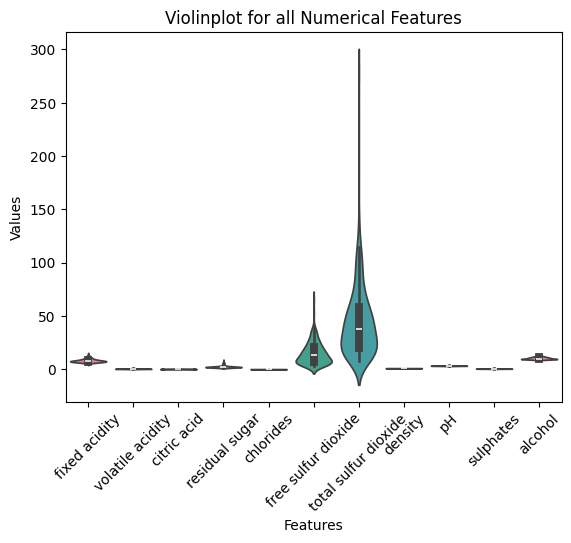

In [6]:
# Plot violinplot of all features
sns.violinplot(data=test.drop(columns=["Id"]))

plt.title("Violinplot for all Numerical Features")
plt.ylabel("Values")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.show()

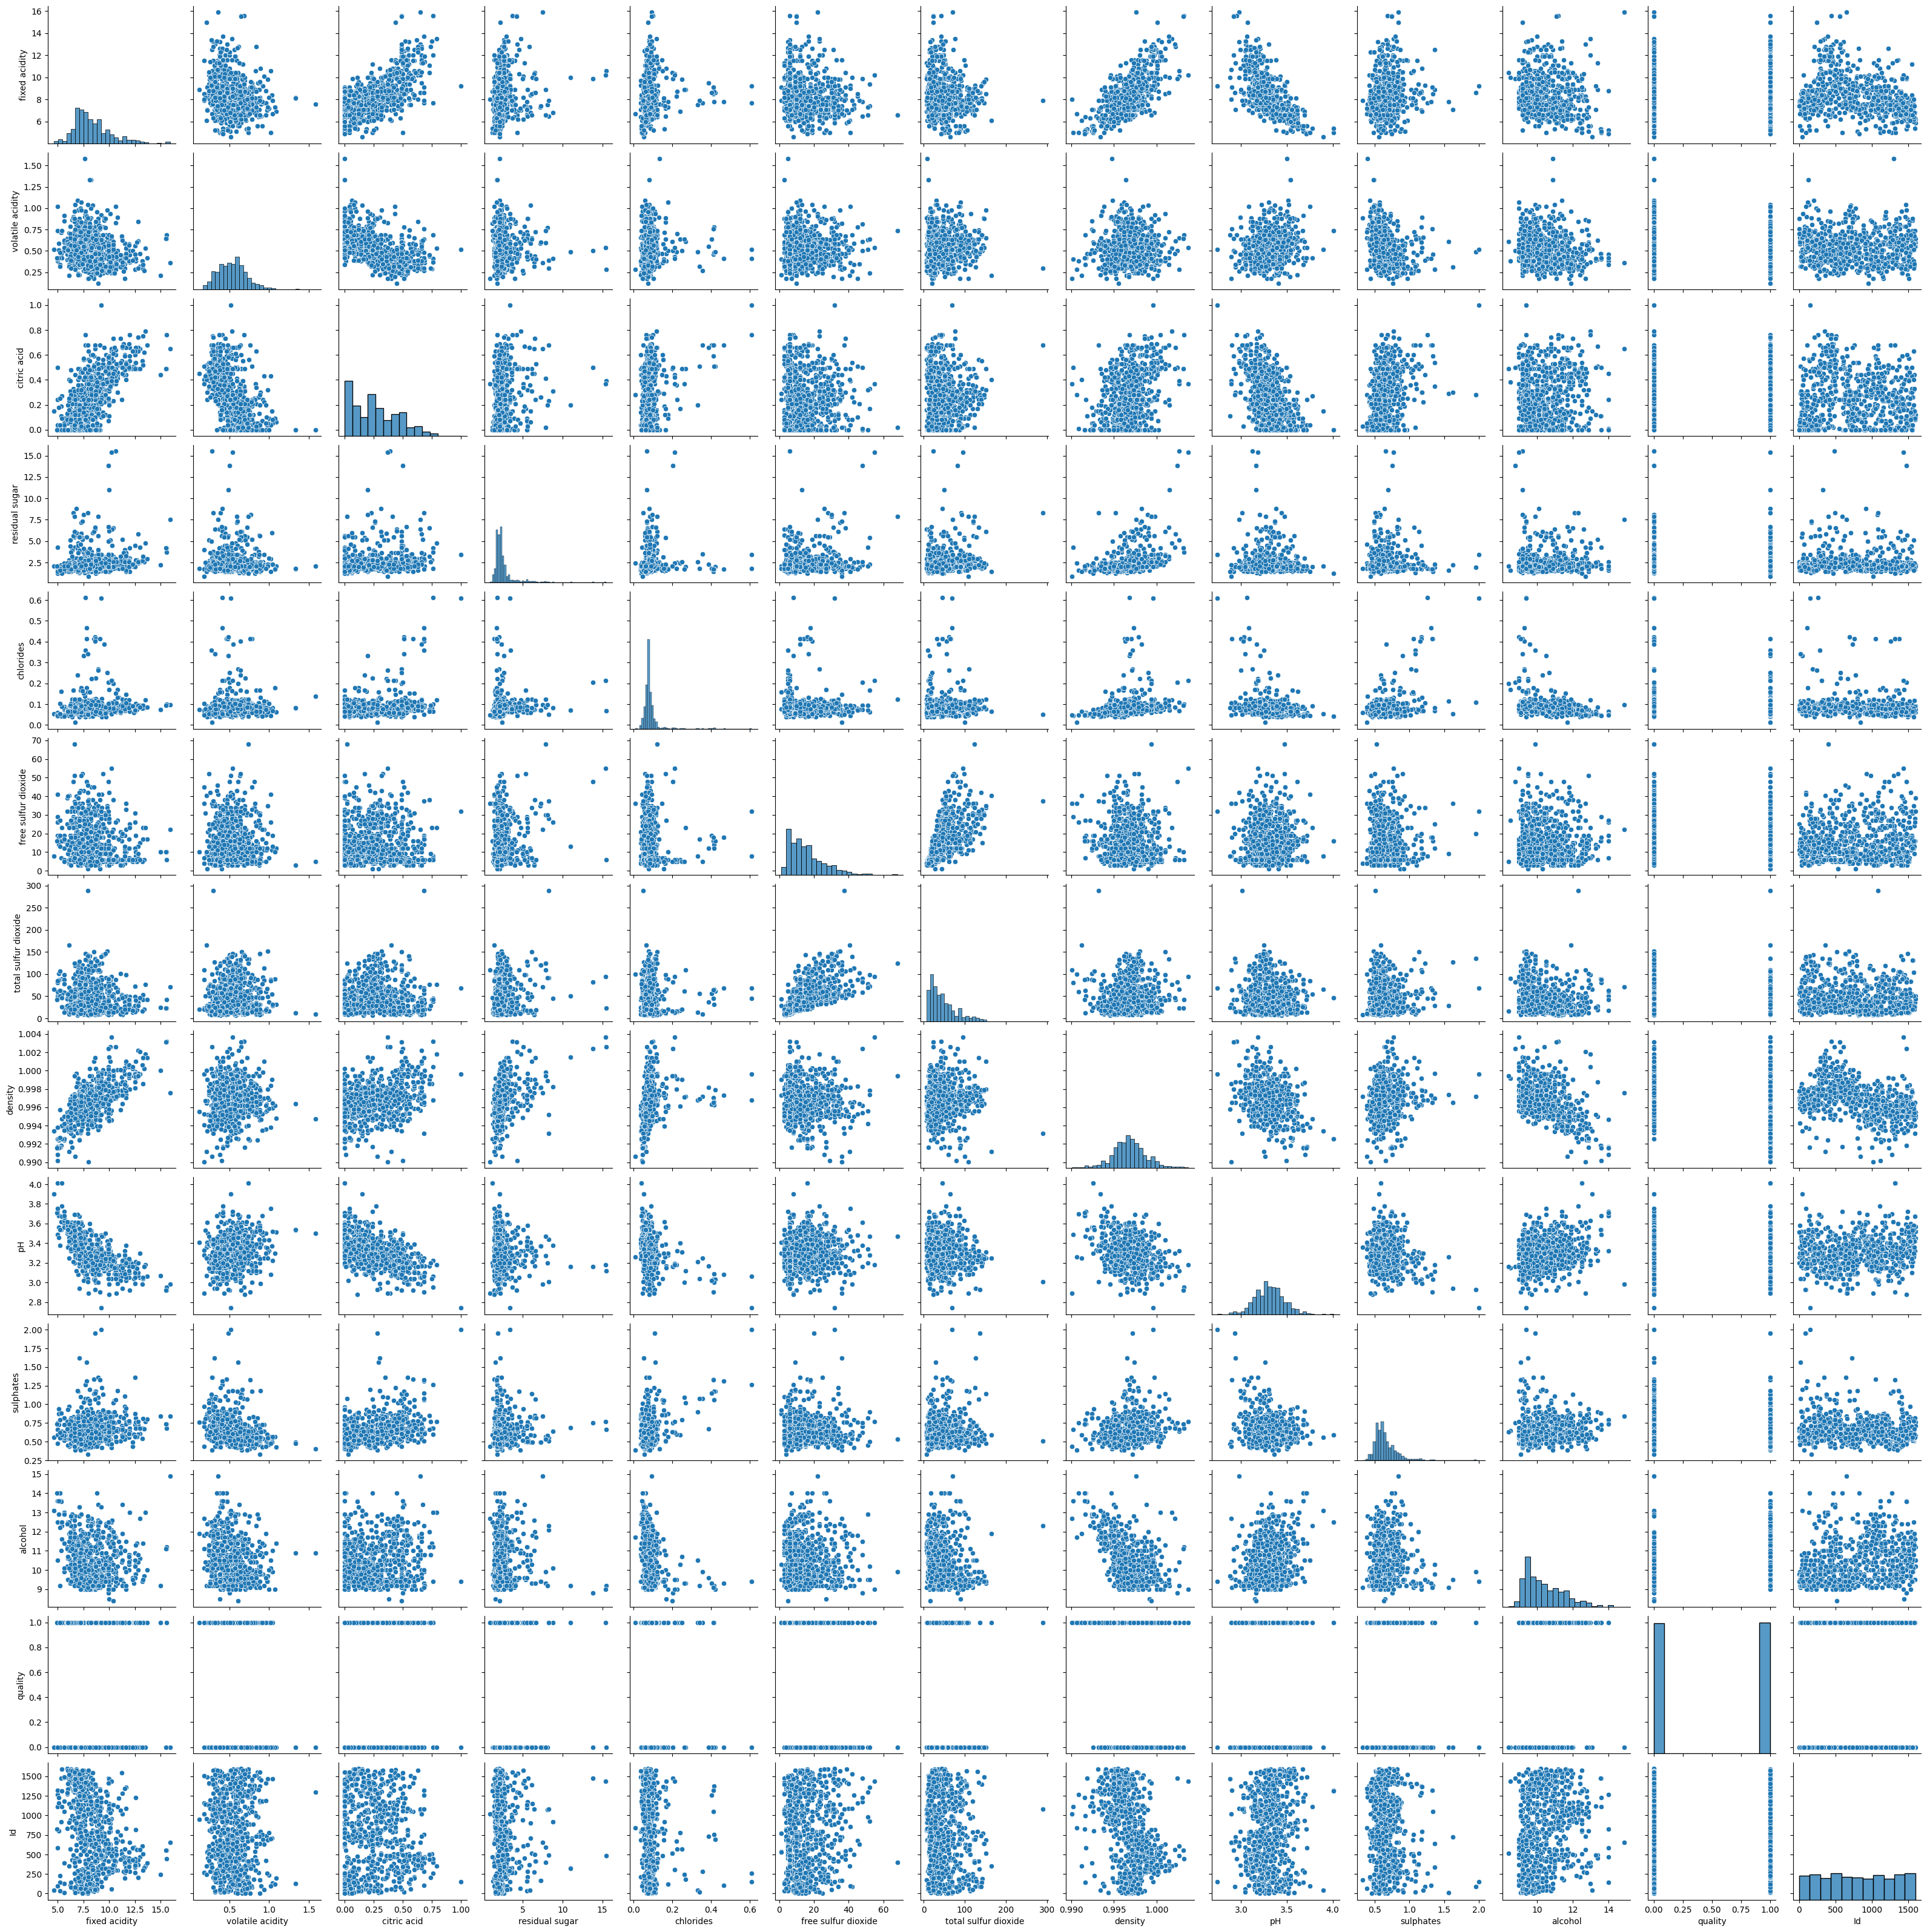

In [7]:
# Plot the pairplot for all variables
sns.pairplot(train)
plt.show()

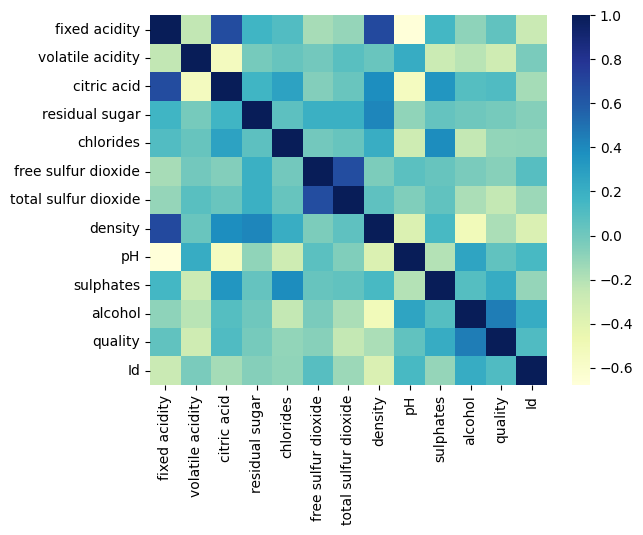

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
fixed acidity,1.000000,-0.239654,0.670481,0.164619,0.107532,-0.162457,-0.110240,0.683265,-0.678121,0.151310,-0.094171,0.051339,-0.274282
volatile acidity,-0.239654,1.000000,-0.535085,-0.019741,0.034499,-0.004585,0.079104,0.023651,0.216863,-0.283993,-0.217002,-0.302238,-0.029563
citric acid,0.670481,-0.535085,1.000000,0.166999,0.277673,-0.061630,0.027693,0.381371,-0.542874,0.338861,0.092857,0.111017,-0.158231
residual sugar,0.164619,-0.019741,0.166999,1.000000,0.063488,0.199822,0.196233,0.410604,-0.098347,0.038467,0.004347,-0.020452,-0.062152
chlorides,0.107532,0.034499,0.277673,0.063488,1.000000,-0.003597,0.034344,0.211559,-0.292120,0.385702,-0.247526,-0.103287,-0.099440
free sulfur dioxide,-0.162457,-0.004585,-0.061630,0.199822,-0.003597,1.000000,0.659305,-0.037447,0.074736,0.032304,-0.035300,-0.074444,0.088745
total sulfur dioxide,-0.110240,0.079104,0.027693,0.196233,0.034344,0.659305,1.000000,0.061933,-0.054809,0.051520,-0.174027,-0.250267,-0.129465
density,0.683265,0.023651,0.381371,0.410604,0.211559,-0.037447,0.061933,1.000000,-0.367657,0.136117,-0.508704,-0.179263,-0.361780
pH,-0.678121,0.216863,-0.542874,-0.098347,-0.292120,0.074736,-0.054809,-0.367657,1.000000,-0.202909,0.261024,0.049578,0.136541
sulphates,0.151310,-0.283993,0.338861,0.038467,0.385702,0.032304,0.051520,0.136117,-0.202909,1.000000,0.093781,0.219372,-0.113689


In [8]:
# Compute correlation matrix
co_mtx = train.corr(numeric_only=True)

# Plot correlation heatmap
sns.heatmap(co_mtx, cmap="YlGnBu", annot=False)

# Display heatmap
plt.show()

# Show correlation matrix
co_mtx

The following variables are moderately correlated:
* "fixed acidity" and "density" : 0.683265
* "fixed acidity" and "citric acid" : 0.670481
* "fixed acidity" and "pH" : -0.678121
* "total sulfur dioxide" and "free sulfur dioxide" : 0.659305


### Data cleaning

Checking for duplicate rows

In [9]:
test.duplicated().sum()

np.int64(0)

Handling missing values

In [10]:
test.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
Id                      0
dtype: int64

Handling outliers

In [11]:
test.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
Id                        int64
dtype: object

**how to remove them for al the variables at once?**

### Data preprocessing and visualisation

Feature standardizing 

**Arew e allowed to use libraries again?**

In [12]:
# Initialise standard scaler and compute mean and sd from training data
features = train.drop(columns=["quality", "Id"]).columns

sc = StandardScaler().set_output(transform="pandas")
sc.fit(train[features])

# Transform (standardise) both X_train and X_test with mean and sd from training data
train_sc = sc.transform(train[features])
test_sc = sc.transform(test[features])

test_sc.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.746395,0.834594,-0.965437,-0.030286,0.045200,-0.082376,-0.784251,-0.554690,0.448452,-0.322877,0.831569
1,-1.088021,-0.389819,0.704428,-0.100728,-0.343493,-0.752972,-0.844400,-0.256431,1.580695,0.400216,0.187450
2,-0.233956,-0.055888,-0.105204,-0.382498,-0.324058,-0.082376,1.741979,-0.410703,-0.243474,-0.656612,-0.916754
3,-0.404769,-0.723750,-0.105204,-0.523383,-0.168581,-1.136170,-1.084993,-0.307855,-0.180571,-0.378499,-0.824737
4,-0.120081,1.836386,-1.319651,-0.241613,-0.090842,-0.561373,-0.483510,-0.122728,-0.369278,-0.879102,-0.548686


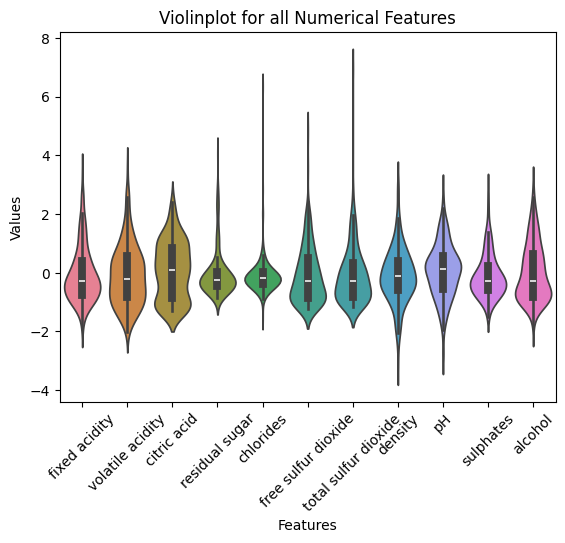

In [13]:
# Plot violinplot of all features after standardizing
sns.violinplot(data=test_sc)

plt.title("Violinplot for all Numerical Features")
plt.ylabel("Values")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.show()

Feature selection

**All features have low correlation with the quality?**

### Modelling

Use the practice of using many train_test_splits (of the training data) while searching for the best (hyper-)parameters of each classifier

In [14]:
X = train_sc
y = train["quality"]

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

First try modelling on the features where correaltion between quality anf the feature is larger than 0.2:
volatile acidity, total sulfur dioxide, sulphates, alcohol

In [16]:
y_train.describe()

count    668.000000
mean       0.500000
std        0.500375
min        0.000000
25%        0.000000
50%        0.500000
75%        1.000000
max        1.000000
Name: quality, dtype: float64

#### Decision Tree

Accuracy on training data: 0.76
Accuracy on test data: 0.74
Features used for plot: ['alcohol', 'sulphates']


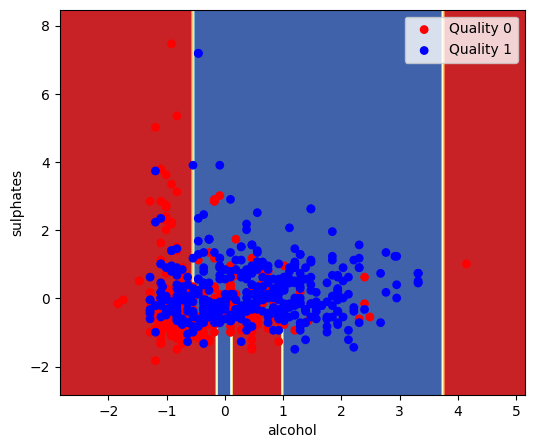

In [17]:
clf = DecisionTreeClassifier(max_depth=3, criterion='gini', min_samples_leaf=1, random_state=42)
clf.fit(X_train, y_train)

print(f'Accuracy on training data: {accuracy_score(y_train, clf.predict(X_train)):.2f}')
print(f'Accuracy on test data: {accuracy_score(y_test, clf.predict(X_test)):.2f}')

# --- Pick the 2 most important features for plotting ---
importances = pd.Series(clf.feature_importances_, index=X.columns)
top2 = importances.nlargest(2).index.tolist()
print('Features used for plot:', top2)

X_2d = X[top2].values
y_arr = np.asarray(y)

# --- Separate 2-feature model, only for visualization ---
clf_2d = DecisionTreeClassifier(max_depth=3, criterion='gini', min_samples_leaf=1, random_state=42)
clf_2d.fit(X_2d, y_arr)

# --- Plot decision boundary ---
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
DecisionBoundaryDisplay.from_estimator(
    clf_2d,
    X_2d,
    cmap=plt.cm.RdYlBu,
    response_method="predict",
    ax=ax,
    xlabel=top2[0],
    ylabel=top2[1],
)

class_names = {0: 'Quality 0', 1: 'Quality 1'}
plot_colors = ["red", "blue"]
for cls, color in zip(np.unique(y_arr), plot_colors):
    idx = np.where(y_arr == cls)
    ax.scatter(
        X_2d[idx, 0],
        X_2d[idx, 1],
        c=color,
        label=class_names[cls],
        edgecolor="none",
        s=40,
    )

ax.legend()
plt.show()

#### kNN

1-Nearest-Neighbor train accuracy: 0.928  test accuracy: 0.766
2-Nearest-Neighbor train accuracy: 0.829  test accuracy: 0.701
3-Nearest-Neighbor train accuracy: 0.811  test accuracy: 0.754
4-Nearest-Neighbor train accuracy: 0.798  test accuracy: 0.725
5-Nearest-Neighbor train accuracy: 0.798  test accuracy: 0.707
6-Nearest-Neighbor train accuracy: 0.778  test accuracy: 0.683
7-Nearest-Neighbor train accuracy: 0.766  test accuracy: 0.695
8-Nearest-Neighbor train accuracy: 0.750  test accuracy: 0.713
9-Nearest-Neighbor train accuracy: 0.760  test accuracy: 0.707
Best k: 1


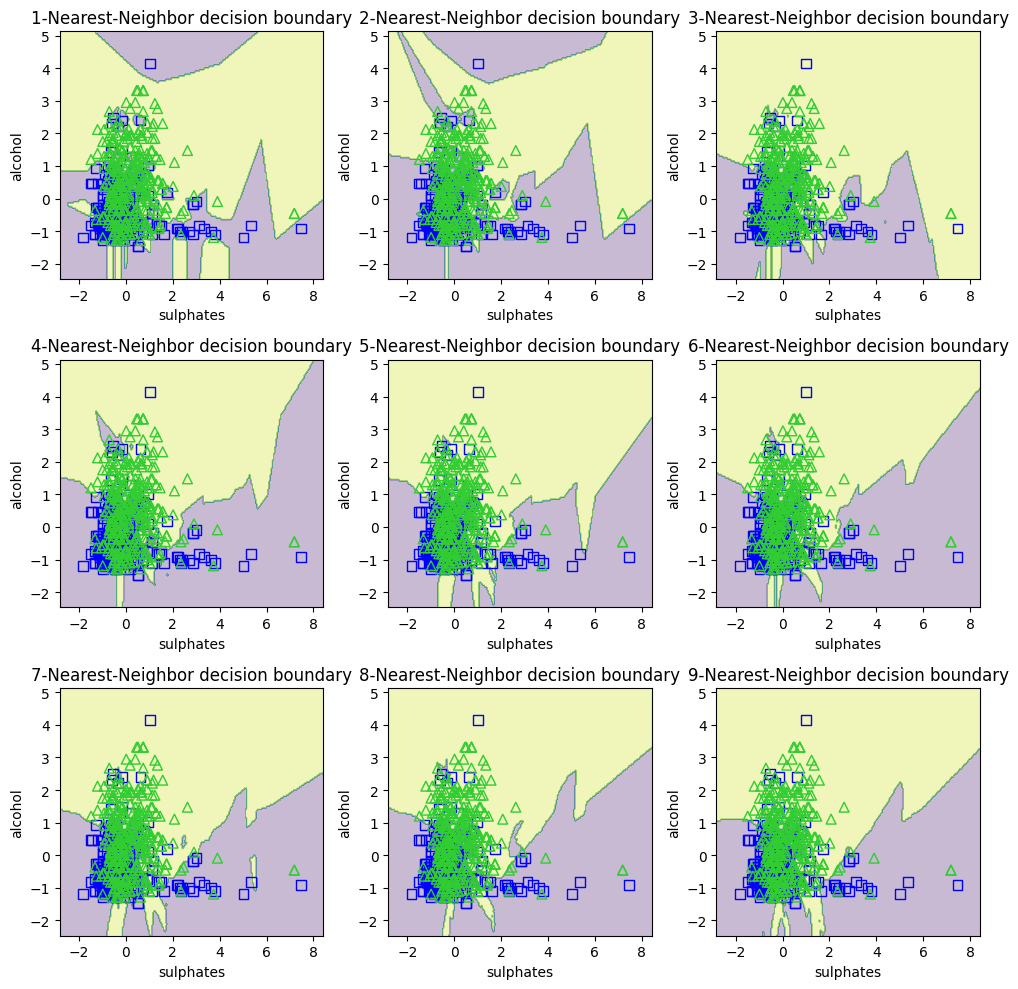

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

# Pick features
feat = ["sulphates", "alcohol"]

# Convert to NumPy so [:, 0] indexing works
Xtr = X_train[feat].values
Xte = X_test[feat].values
ytr = np.asarray(y_train)
yte = np.asarray(y_test)

# Train KNN for k=1..9
clfs = []
for k in range(1, 10):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(Xtr, ytr)
    clfs.append(knn)

# Grid for decision boundaries
fig, ax = plt.subplots(3, 3, figsize=(10, 10))
ax = ax.flatten()
h = 0.05
x_min, x_max = Xtr[:, 0].min() - 1, Xtr[:, 0].max() + 1
y_min, y_max = Xtr[:, 1].min() - 1, Xtr[:, 1].max() + 1   # fixed: Xtr, not y_train
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
X_predict = np.c_[xx.ravel(), yy.ravel()]

accuracy = []
for clf, name, a in zip(clfs, [f"{k}-Nearest-Neighbor" for k in range(1, 10)], ax):
    Z = clf.predict(X_predict).reshape(xx.shape)
    a.contourf(xx, yy, Z, alpha=0.3)
    a.set_title(f"{name} decision boundary")
    a.set_xlabel(feat[0])
    a.set_ylabel(feat[1])

    test_accuracy = np.mean(clf.predict(Xte) == yte)
    train_accuracy = np.mean(clf.predict(Xtr) == ytr)
    print(f"{name} train accuracy: {train_accuracy:.3f}  test accuracy: {test_accuracy:.3f}")
    accuracy.append(test_accuracy)

best_k = np.argmax(accuracy) + 1
print(f"Best k: {best_k}")

# Plot the training data
colors, markers = ["blue", "limegreen", "gray", "cyan"], "s^oxv<>"
for a in ax:
    for i, cls in enumerate(np.unique(ytr)):
        a.scatter(Xtr[ytr == cls, 0], Xtr[ytr == cls, 1],
                  color=colors[i], marker=markers[i], s=50, facecolors="none")

fig.tight_layout()
plt.show()

The data seems to overlap quiet a lot, so we want to examine whether we can classify the quality better, by testing different kernel models; 
* Kernel SVM
* Kernel Perceptron
* Kernel Logistic Regression
* Kernel Ridge Regression (linear regression + L2 regularizer)
* Kernel k-nearest neighbours

#### Kernel SVM

In [19]:
import time
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1) Subsample for the separability check (training accuracy only needs the train set)
n = min(2000, len(X_train))
Xs = X_train.iloc[:n]
ys = y_train.iloc[:n] if hasattr(y_train, "iloc") else y_train[:n]

# 2) Moderate C, an iteration cap, and a bigger kernel cache
kernels = {
    "linear":       SVC(kernel="linear", C=1000, max_iter=100_000, cache_size=1000),
    "poly (deg 2)": SVC(kernel="poly", degree=2, C=1000, max_iter=100_000, cache_size=1000),
    "poly (deg 3)": SVC(kernel="poly", degree=3, C=1000, max_iter=100_000, cache_size=1000),
    "rbf":          SVC(kernel="rbf", gamma="scale", C=1000, max_iter=100_000, cache_size=1000),
}

for name, svm in kernels.items():
    t0 = time.time()
    svm.fit(Xs, ys)
    tr = accuracy_score(ys, svm.predict(Xs))
    print(f"{name:14s} train: {tr:.3f}  ({time.time() - t0:.1f}s)")

c:\Users\kikib\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


linear         train: 0.638  (0.7s)


c:\Users\kikib\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


poly (deg 2)   train: 0.756  (0.5s)


c:\Users\kikib\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


poly (deg 3)   train: 0.922  (0.4s)
rbf            train: 0.993  (0.2s)


#### Kernel Perceptron

In [20]:
class Perceptron:
    def __init__(self, epochs=50, learning_rate=0.1):
        self.epochs = epochs
        self.learning_rate = learning_rate

    def predict(self, X):
        return np.sign(self.predict_value(X))

    def predict_value(self, X):
        return np.dot(X, self.parameters[1:]) + self.parameters[0]

    def fit(self, X, Y):
        if (np.unique(Y) != np.array([-1, 1])).any():
            raise ValueError("Labels must be -1 and 1")

        self.parameters = np.zeros(X.shape[1]+1)
        for _ in range(self.epochs):
            for x, y in zip(X, Y):
                diff = y - self.predict(x.reshape(1, -1))
                self.parameters[1:] += self.learning_rate * diff * x
                self.parameters[0] += self.learning_rate * diff.item()


class KernelPerceptron:
    def __init__(self, kernel, epochs=50, learning_rate=0.1):
        self.kernel = kernel
        self.epochs = epochs
        self.learning_rate = learning_rate

    def predict(self, X):
        return np.sign(self.predict_value(X))

    def predict_value(self, X):
        return np.dot(self.kernel(X), self.parameters)

    def fit(self, X, Y):
        if (np.unique(Y) != np.array([-1, 1])).any():
            raise ValueError("Labels must be -1 and 1")

        self.parameters = np.zeros(X.shape[0])
        for _ in range(self.epochs):
            for i, (x, y) in enumerate(zip(X, Y)):
                diff = y - self.predict(x.reshape(1, -1))
                self.parameters[i] += self.learning_rate * diff.item()


class OneVersusRestClassifier:
    def __init__(self, classifier):
        self.clf = classifier

    def predict(self, X):
        numbered_class = np.argmax([c.predict_value(X) for c in self.clfs], axis=0)
        return self.unique[numbered_class]

    def fit(self, X, Y):
        self.unique, y = np.unique(Y, return_inverse=True)
        num_classes = len(self.unique)
        self.clfs = [copy.deepcopy(self.clf) for _ in range(num_classes)]
        for i in range(num_classes):
            y_binary = np.array([1 if yy == i else -1 for yy in y])
            self.clfs[i].fit(X, y_binary)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 11 is different from 2)

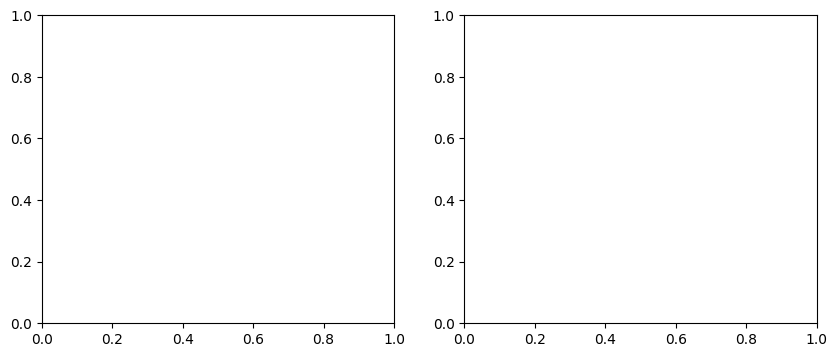

In [21]:
import copy
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 0. Make sure the data are NumPy arrays (fixes the 'str' error:
#    iterating over a DataFrame yields column names, not rows)
# ---------------------------------------------------------------
X_train = np.asarray(X_train, dtype=float)   # shape (n_samples, 2)
y_train = np.asarray(y_train)                # shape (n_samples,)

# ---------------------------------------------------------------
# 1. Kernels: K(A, B) returns a matrix of shape (len(A), len(B)).
#    Both inputs are passed explicitly (no global X).
# ---------------------------------------------------------------
def linear_kernel(A, B):
    return A @ B.T + 1                       # +1 acts as the bias term

def polynomial_kernel(A, B, degree=5):
    return (A @ B.T + 1) ** degree

def rbf_kernel(A, B, gamma=0.1):
    # Squared Euclidean distance between every row of A and every row of B
    sq_dists = np.sum((A[:, None, :] - B[None, :, :]) ** 2, axis=-1)
    return np.exp(-gamma * sq_dists)

# ---------------------------------------------------------------
# 2. Ordinary (primal) perceptron, binary labels in {-1, +1}
# ---------------------------------------------------------------
class Perceptron:
    def __init__(self, learning_rate=1.0, epochs=100):
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, Y):
        X = np.asarray(X, dtype=float)
        Y = np.asarray(Y)
        self.w = np.zeros(X.shape[1])        # weight vector
        self.b = 0.0                         # bias
        for _ in range(self.epochs):
            mistakes = 0
            for x, y in zip(X, Y):
                # Mistake-driven update: only change w when misclassified
                if y * (x @ self.w + self.b) <= 0:
                    self.w += self.learning_rate * y * x
                    self.b += self.learning_rate * y
                    mistakes += 1
            if mistakes == 0:                # converged (data separable)
                break
        return self

    def decision_function(self, X):
        # Raw score; its sign is the predicted class
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

# ---------------------------------------------------------------
# 3. Kernel (dual) perceptron
#    score(x) = sum_i alpha_i * y_i * K(x_i, x)
# ---------------------------------------------------------------
class KernelPerceptron:
    def __init__(self, kernel=linear_kernel, learning_rate=1.0, epochs=100):
        self.kernel = kernel
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, Y):
        self.X_train = np.asarray(X, dtype=float)   # kept for prediction
        self.Y_train = np.asarray(Y)
        n = len(self.X_train)
        self.alpha = np.zeros(n)                    # mistake counts per sample
        K = self.kernel(self.X_train, self.X_train) # Gram matrix, computed once
        for _ in range(self.epochs):
            mistakes = 0
            for i in range(n):
                score = K[i] @ (self.alpha * self.Y_train)
                if self.Y_train[i] * score <= 0:    # misclassified
                    self.alpha[i] += self.learning_rate
                    mistakes += 1
            if mistakes == 0:
                break
        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        K = self.kernel(X, self.X_train)            # (n_query, n_train)
        return K @ (self.alpha * self.Y_train)

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

# ---------------------------------------------------------------
# 4. One-versus-rest wrapper for multiclass problems
#    Trains one binary classifier per class (class k = +1, rest = -1)
# ---------------------------------------------------------------
class OneVersusRestClassifier:
    def __init__(self, classifier):
        self.classifier = classifier        # a prototype, copied per class

    def fit(self, X, Y):
        X = np.asarray(X, dtype=float)
        Y = np.asarray(Y)
        self.classes_ = np.unique(Y)
        # deepcopy so each class gets its own independent classifier
        self.clfs = [copy.deepcopy(self.classifier) for _ in self.classes_]
        for clf, c in zip(self.clfs, self.classes_):
            y_binary = np.where(Y == c, 1, -1)      # uses the argument Y
            clf.fit(X, y_binary)
        return self

    def predict(self, X):
        # Score of every class's classifier; pick the class with highest score
        scores = np.column_stack([clf.decision_function(X) for clf in self.clfs])
        return self.classes_[np.argmax(scores, axis=1)]

# ---------------------------------------------------------------
# 5. Train both models
# ---------------------------------------------------------------
perceptron = OneVersusRestClassifier(Perceptron())
kernel_perceptron = OneVersusRestClassifier(
    KernelPerceptron(kernel=polynomial_kernel)      # try rbf_kernel too
)
perceptron.fit(X_train, y_train)
kernel_perceptron.fit(X_train, y_train)

# ---------------------------------------------------------------
# 6. Build a grid covering the data for the decision regions
# ---------------------------------------------------------------
h = 0.05                                            # grid step size
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
X_grid = np.c_[xx.ravel(), yy.ravel()]

# ---------------------------------------------------------------
# 7. Plot decision regions, misclassified points and accuracy
# ---------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
classes = np.unique(y_train)
colors = ["blue", "limegreen", "gray", "cyan"]
markers = ["s", "^", "o", "v"]

for clf, name, a in zip([perceptron, kernel_perceptron],
                        ["Perceptron", "Kernel Perceptron"], ax):
    # Predicted class for every grid point -> coloured regions
    Z = clf.predict(X_grid).reshape(xx.shape)
    a.contourf(xx, yy, Z, alpha=0.3)
    a.set_title(f"{name} decision boundary")

    # Training predictions: used for accuracy and for marking errors
    y_pred = clf.predict(X_train)
    wrong = y_train != y_pred
    print(f"{name} accuracy: {np.mean(~wrong):.3f}")

    # Draw the training points, one class at a time
    for i, c in enumerate(classes):
        mask = y_train == c
        a.scatter(X_train[mask, 0], X_train[mask, 1],
                  facecolors="none", edgecolors=colors[i % len(colors)],
                  marker=markers[i % len(markers)], s=50)

    # Misclassified points on top, as red crosses
    a.scatter(X_train[wrong, 0], X_train[wrong, 1],
              color="r", marker="x", s=30, zorder=3)

fig.tight_layout()
plt.show()

#### Check Lecture_08_09_SVM_Kernels and other kernel (kernel knn, kernel logistic, kernel ridge) to see what performs best 

### Final evaluation

### Kaggle submission

### References: 
* https://stackoverflow.com/questions/64161419/how-can-i-convert-the-standardscaler-transformation-back-to-dataframe
* https://scikit-learn.org/stable/modules/svm.html
* https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html